---
title: "Target the Right Customers with Thinking Mode"
description: "Rank 200,000 bank customers by how likely they are to transact, then decide how many to contact by weighing the cost of a contact against the value of a transaction."
cookbookTags:
  - thinking mode
  - api
  - classification
authors:
  - name: Kürşat Kaya
    linkedin: https://www.linkedin.com/in/kursatkaya/
featured: true
---
A bank has 200,000 customers and wants to know which of them will make a particular
kind of transaction in the coming period. It is important for the bank to put the
right customers at the top of a list, because the list is what the business acts on. A campaign
reaches the first 1%, 5% or 20% of it, and everyone further down is never contacted.

This creates two practical decisions: how to rank customers and how many of them the campaign should contact.

This notebook fits an XGBoost baseline and the base TabPFN 3.5 model on the
[Santander Customer Transaction Prediction](https://www.kaggle.com/c/santander-customer-transaction-prediction)
dataset, then runs Thinking mode twice, once optimizing ROC AUC and once average
precision. It compares the four models the way a campaign would: by how many
transactors each list reaches at fixed contact budgets, and by the net value of a
simulated campaign at every size.

## Setup

Install the client, XGBoost and the other dependencies. In Colab, add `TABPFN_TOKEN` to Secrets; elsewhere, use your usual client authentication.

In [ ]:
%pip install -q --upgrade tabpfn-client==0.7.1 pandas==2.3.3 numpy==2.5.3 scikit-learn==1.9.0 matplotlib==3.11.2 pyarrow==25.0.1 huggingface-hub==1.31.0 xgboost==3.4.1 ipywidgets==8.1.5

In [2]:
import os

try:
    from google.colab import userdata
except ImportError:
    pass
else:
    os.environ["TABPFN_TOKEN"] = userdata.get("TABPFN_TOKEN")

In [ ]:
import json
import time
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download
from IPython.display import display
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score

from xgboost import XGBClassifier
from tabpfn_client import TabPFNClassifier

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})

## The data

We use the [BeyondArena](https://huggingface.co/datasets/TabArena/BeyondArena) copy
of the Kaggle training set: 200,000 customers, a binary target, and 200 anonymized
numeric features. BeyondArena adds two indicator columns per feature that encode
whether a value is unique in the dataset, a pattern the competition's top entries
relied on, which brings the width to 600 columns. The features have no names and
no documented meaning, so there is nothing to engineer by hand. Because the features
are anonymized, we compare the models without domain-specific feature engineering.

BeyondArena publishes fixed splits. We take the first fold of the first repetition:
133,333 customers to train on and 66,667 held out. Credit: Santander Bank via
[Kaggle](https://www.kaggle.com/competitions/santander-customer-transaction-prediction), used under the competition rules.

In [4]:
def download_file(filename):
    return hf_hub_download(
        "TabArena/BeyondArena",
        f"santander_customer_transaction_prediction/019d7373-33b4-7002-948b-c14d1fffe341/{filename}",
        repo_type="dataset", revision="88059a3f02ec4abb6ec24bbe0d1c0b7eed31485d",
    )

customers = pd.read_parquet(download_file("dataset.parquet"))
published_splits = json.loads(Path(download_file(
    "experiment_metadata.predictive-ml-splits-mold-v1.json"
)).read_text())["splits"]
train_idx, test_idx = published_splits["0"]["0"]

X_train = customers.iloc[train_idx].drop(columns="target")
y_train = customers.iloc[train_idx]["target"].to_numpy()
X_test = customers.iloc[test_idx].drop(columns="target")
y_test = customers.iloc[test_idx]["target"].to_numpy()
print(f"{len(X_train):,} training customers; {len(X_test):,} held-out customers; "
      f"{X_train.shape[1]} features; {y_train.mean():.1%} transact")

133,333 training customers; 66,667 held-out customers; 600 features; 10.0% transact


## What to measure

A campaign does not act on the whole ranking. It contacts the top of it, down to a
budget, so we evaluate every model at four budgets: the top 1%, 5%, 10% and 20% of
customers. At each budget we report:

- **Customers contacted** and **transactors captured**, as counts.
- **Precision**: the share of contacted customers who transact.
- **Lift**: precision divided by the 10% base rate, that is, how many times better
  the list does than contacting customers at random.
- **Net value** of the simulated campaign, under the cost and value assumptions set
  further down.

We also report ROC AUC, average precision, and log-loss. **ROC AUC**, the dataset's own
objective, measures ranking quality everywhere. **Average precision** weights the
top of the list, where campaigns operate. **Log-loss** measures whether the
probabilities are calibrated, which matters further down, where we use them to
plan a campaign size.

In [5]:
BUDGETS = [0.01, 0.05, 0.10, 0.20]


def fit_and_score(model):
    """Fit on the training customers and return held-out scores and fit minutes."""
    started = time.perf_counter()
    model.fit(X_train, y_train)
    minutes = (time.perf_counter() - started) / 60
    probability = np.asarray(model.predict_proba(X_test), dtype=float)
    probability /= probability.sum(axis=1, keepdims=True)
    return probability[:, 1], minutes


def list_metrics(score, y_true):
    return {"ROC AUC": roc_auc_score(y_true, score),
            "Avg precision": average_precision_score(y_true, score),
            "Log-loss": log_loss(y_true, score)}


def net_value_curve(score, y_true, contact_cost, transaction_value):
    """Simulated net value of contacting the top k customers of the ranking, for every k."""
    order = np.argsort(-score)
    contacted = np.arange(1, len(order) + 1)
    return transaction_value * np.cumsum(y_true[order]) - contact_cost * contacted


def campaign_table(scores, y_true, budgets, contact_cost, transaction_value):
    """Simulated campaign at each budget for every model, with the gap to the best model."""
    rows = []
    for budget in budgets:
        n_contacted = int(round(budget * len(y_true)))
        for name, score in scores.items():
            captured = int(y_true[np.argsort(-score)[:n_contacted]].sum())
            rows.append({"Budget": f"{budget:.0%}", "Model": name,
                         "Contacted": n_contacted,
                         "Transactors captured": captured,
                         "Precision": captured / n_contacted,
                         "Lift": captured / n_contacted / y_true.mean(),
                         "Net value (€)": captured * transaction_value - n_contacted * contact_cost})
    table = pd.DataFrame(rows)
    best = table.groupby("Budget")["Net value (€)"].transform("max")
    table["Opportunity cost (€)"] = best - table["Net value (€)"]
    return table.set_index(["Budget", "Model"])

## Base model: TabPFN 3.5

On the API the fit itself takes a few seconds; the time
below is mostly uploading 133,000 rows.

In [6]:
scores, minutes = {}, {}
scores["Base model"], minutes["Base model"] = fit_and_score(TabPFNClassifier(random_state=0))
print(f"Base model: fit {minutes['Base model']:.1f} min")

Base model: fit 0.2 min


## Baseline: XGBoost

We include XGBoost as a conventional tabular baseline. 
We use shallow trees and a small learning rate, settings that suit many weak,
independent features, and fit once with them fixed. Nothing is tuned on the
held-out customers, so the comparison stays fair.

In [7]:
xgb = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=2, subsample=0.8,
                    colsample_bytree=0.5, random_state=0, n_jobs=-1)
scores["XGBoost"], minutes["XGBoost"] = fit_and_score(xgb)
print(f"XGBoost: fit {minutes['XGBoost']:.1f} min")

XGBoost: fit 0.5 min


## Thinking mode with two objectives

Thinking changes what happens at fit time. Instead of a single forward pass, the
server runs an optimization over the training data against the metric named in
`thinking_metric`, then serves the result for every later prediction. We compare
roc_auc with average_precision to test whether optimizing for the top of the
ranking improves small campaigns. `"roc_auc"` rewards a good ranking everywhere in
the list; `"average_precision"` rewards getting the top of the list right, which is
the only part a small campaign ever sees.

We fit one model for each objective using the same "micro" effort level. thinking_effort controls the fit-time optimization budget; available levels depend on the client version and account access. On this dataset, each "micro" fit takes approximately 5.7 minutes.

In [8]:
EFFORT = "micro"

for metric in ["roc_auc", "average_precision"]:
    name = f"Thinking ({metric})"
    model = TabPFNClassifier(random_state=0, thinking_effort=EFFORT, thinking_metric=metric)
    scores[name], minutes[name] = fit_and_score(model)
    print(f"{name}: fit {minutes[name]:.1f} min")

Thinking (roc_auc): fit 5.7 min
Thinking (average_precision): fit 5.7 min


## Ranking quality

In [9]:
summary = pd.DataFrame({name: {**list_metrics(score, y_test), "Fit minutes": minutes[name]}
                        for name, score in scores.items()}).T
display(summary.round(4))

,ROC AUC,Avg precision,Log-loss,Fit minutes
Base model,0.8951,0.6025,0.2058,0.2414
XGBoost,0.8872,0.5880,0.2261,0.5111
Thinking (roc_auc),0.9074,0.6477,0.1950,5.6969
Thinking (average_precision),0.9074,0.6477,0.1951,5.6823


Both Thinking objectives produce the same whole-list results: ROC AUC 0.9074 and average precision 0.6477, compared with 0.8951 and 0.6025 for the base model. XGBoost trails both TabPFN variants, with ROC AUC 0.8872 and average precision 0.5880. Relative to base TabPFN, Thinking increases average precision from 0.6025 to 0.6477.

## Campaign assumptions

To turn a ranking into money we need two numbers, both set in the cell below:

- **Value per transaction**: what one transaction is worth to the bank. Default
  €100.
- **Cost per contact**: what one call, email or mailing costs. Default €2.

The net value of contacting the top *k* customers of a list is

net value = (transactors captured × value per transaction) − (customers contacted × cost per contact).

These defaults are illustrative, not Santander's figures. Change them to your own
and rerun the cells below. With them, a contact breaks even once 2% of the
contacted customers transact (cost ÷ value).

**This is a simulation based on predicted outcomes, not causal uplift.** It counts
every contacted customer who transacts as a transaction the campaign won. In
practice some of them would have transacted without being contacted, so the real
value of a campaign is lower and has to be measured with a randomized control
group. The numbers also cover only the 66,667 held-out customers, a third of the
customer base. Use them to compare models, not as a forecast of campaign revenue.

In [10]:
TRANSACTION_VALUE = 100.0  # assumed value of one transaction, in euros
CONTACT_COST = 2.0         # assumed cost of one contact, in euros

## Simulated campaigns at each budget

The last column is an **opportunity cost**: how much less net value a model's list
produces than the best list at the same budget on these held-out customers. It is
the gap between two simulated campaigns, not a proven financial loss. A different
split, other assumptions or a real campaign would move it.

In [11]:
campaigns = campaign_table(scores, y_test, BUDGETS, CONTACT_COST, TRANSACTION_VALUE)
display(campaigns.style.format({
    "Contacted": "{:,}", "Transactors captured": "{:,}", "Precision": "{:.1%}",
    "Lift": "{:.2f}", "Net value (€)": "€{:,.0f}", "Opportunity cost (€)": "€{:,.0f}"}))

Thinking produces the highest simulated value at every campaign budget. The two Thinking objectives are within a handful of transactors of each other at every budget, for example 639 and 636 in the top 1%, so neither objective has a meaningful edge here.

At the 10% budget, Thinking with ROC-AUC optimization produces €384,666 in simulated value, compared with €366,166 for base TabPFN and €355,766 for XGBoost. Under these assumptions, XGBoost’s opportunity cost is €28,900. At 20%, that gap grows to €32,000.

## The optimal campaign size

The net value curve rises while each extra contact is more likely than the
break-even rate to transact, and falls once it is less likely. Its peak is the
economically optimal contact fraction under the assumptions above.

On the held-out set we can read the peak off the realized outcomes. Before a real
campaign the outcomes are unknown, so a team has to plan the size from the model's
own probabilities: contact every customer whose predicted chance of transacting is
above cost ÷ value. The table shows both. The gap between the planned and the best
campaign is what imperfect calibration costs.

In [12]:
break_even = CONTACT_COST / TRANSACTION_VALUE
rows = []
for name, score in scores.items():
    net = net_value_curve(score, y_test, CONTACT_COST, TRANSACTION_VALUE)
    best = net.argmax()
    planned = int((score > break_even).sum())
    rows.append({"Model": name,
                 "Best fraction": (best + 1) / len(score),
                 "Best net value (€)": net[best],
                 "Planned fraction": planned / len(score),
                 "Planned net value (€)": net[planned - 1] if planned else 0.0})
decisions = pd.DataFrame(rows).set_index("Model")
display(decisions.style.format({"Best fraction": "{:.1%}", "Planned fraction": "{:.1%}",
                                "Best net value (€)": "€{:,.0f}",
                                "Planned net value (€)": "€{:,.0f}"}))

,Best fraction,Best net value (€),Planned fraction,Planned net value (€)
Model,,,,
Base model,53.4%,"€569,206",61.6%,"€568,128"
XGBoost,59.5%,"€564,148",91.4%,"€546,994"
Thinking (roc_auc),50.0%,"€571,144",55.0%,"€570,602"
Thinking (average_precision),52.6%,"€571,056",57.3%,"€570,636"


The left panel is a gains curve: contact the top x% of the ranked list, and the
curve shows what share of all transactors you reach, with the four budgets marked.
The right panel is net value against campaign size, with each model's optimum
marked. Both dotted lines are a random list.

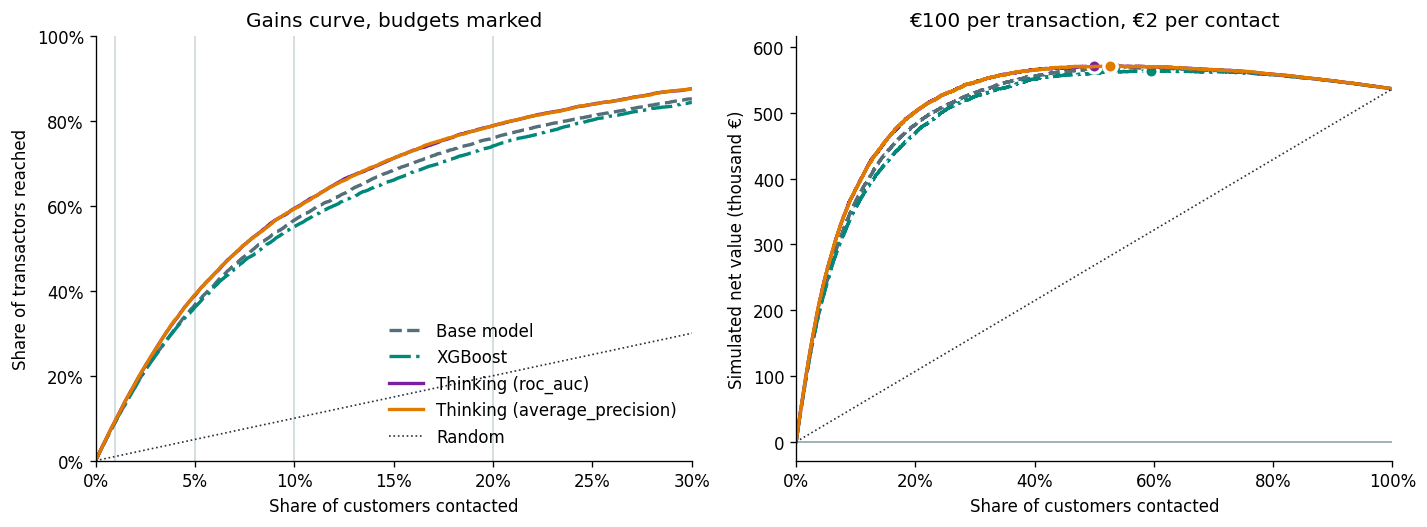

In [13]:
styles = {"XGBoost": {"color": "#00897B", "linestyle": "-."},
          "Base model": {"color": "#546E7A", "linestyle": "--"},
          "Thinking (roc_auc)": {"color": "#7B1FA2", "linestyle": "-"},
          "Thinking (average_precision)": {"color": "#E07B00", "linestyle": "-"}}
contacted = np.arange(1, len(y_test) + 1) / len(y_test)


def plot_net_value(ax, contact_cost, transaction_value, legend=False):
    """Simulated net value against campaign size, with each model's optimum marked.

    The x axis runs to twice the largest optimum, so the profitable region stays readable.
    """
    curves = {name: net_value_curve(score, y_test, contact_cost, transaction_value) / 1000
              for name, score in scores.items()}
    random_net = (transaction_value * y_test.mean() - contact_cost) * np.arange(1, len(y_test) + 1) / 1000
    x_max = min(1.0, max(0.2, 2 * max(contacted[net.argmax()] for net in curves.values())))
    visible = contacted <= x_max
    for name, net in curves.items():
        best = net.argmax()
        ax.plot(contacted, net, linewidth=2, label=name, **styles[name])
        ax.plot(contacted[best], net[best], "o", markersize=8,
                color=styles[name]["color"], markeredgecolor="white", markeredgewidth=2)
    ax.plot(contacted, random_net, color="#263238", linestyle=":", linewidth=1, label="Random")
    ax.axhline(0, color="#90a4ae", linewidth=1, zorder=0)
    low = min(0, *(net[visible].min() for net in curves.values()))
    high = max(net[visible].max() for net in curves.values())
    ax.set_ylim(low - 0.05 * (high - low), high + 0.08 * (high - low))
    ax.set_xlim(0, x_max)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x * 100:g}%")
    ax.set(xlabel="Share of customers contacted", ylabel="Simulated net value (thousand €)",
           title=f"€{transaction_value:g} per transaction, €{contact_cost:g} per contact")
    if legend:
        ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)

fig, (gains, value) = plt.subplots(1, 2, figsize=(12, 4.5))
for name, score in scores.items():
    order = np.argsort(-score)
    gains.plot(contacted, np.cumsum(y_test[order]) / y_test.sum(), linewidth=2,
               label=name, **styles[name])
gains.plot([0, 1], [0, 1], color="#263238", linestyle=":", linewidth=1, label="Random")
for budget in BUDGETS:
    gains.axvline(budget, color="#cfd8dc", linewidth=1, zorder=0)
gains.set_xlim(0, 0.3)
gains.set_ylim(0, 1)
gains.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
gains.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
gains.set(xlabel="Share of customers contacted", ylabel="Share of transactors reached",
          title="Gains curve, budgets marked")
gains.legend(frameon=False, loc="lower right")
plot_net_value(value, CONTACT_COST, TRANSACTION_VALUE)
fig.tight_layout()
plt.show()

With a €100 transaction value and €2 contact cost, the realized net-value curves of the two Thinking models peak after contacting 50–53% of customers. Their maximum values are almost identical: €571,144 for ROC-AUC optimization and €571,056 for average-precision optimization.

The probability-based plans come close to those hindsight optima. They reach €570,602 and €570,636 respectively, less than €550 below the best possible value on the held-out outcomes. XGBoost’s planned campaign is much larger—91.4% of customers—and produces €546,994, €17,154 below its own hindsight optimum. This reflects its weaker probability estimates as well as its weaker ranking.

## Try your own assumptions

Move the sliders to set your own
value per transaction and cost per contact: the simulated net value, the
opportunity cost of each model and the net value curve update when you release a
slider. The sliders need a running notebook, in Colab, Jupyter or VS Code; on a
static page you see only the code.

These values compare model rankings under illustrative assumptions; they do not estimate causal campaign impact.

In [14]:
def explore(transaction_value, contact_cost):
    table = campaign_table(scores, y_test, BUDGETS, contact_cost, transaction_value)
    budgets, models = [f"{b:.0%}" for b in BUDGETS], list(scores)
    print(f"Break-even precision: {contact_cost / transaction_value:.1%} of contacted customers")
    display(table["Net value (€)"].unstack("Model").loc[budgets, models].style
            .format("€{:,.0f}").set_caption("Simulated net value at each budget"))
    display(table["Opportunity cost (€)"].unstack("Model").loc[budgets, models].style
            .format("€{:,.0f}").set_caption("Opportunity cost: gap to the best model at the same budget"))
    optima = {name: net_value_curve(score, y_test, contact_cost, transaction_value)
              for name, score in scores.items()}
    display(pd.DataFrame({"Best fraction": {n: (net.argmax() + 1) / len(net) for n, net in optima.items()},
                          "Best net value (€)": {n: net.max() for n, net in optima.items()}})
            .style.format({"Best fraction": "{:.1%}", "Best net value (€)": "€{:,.0f}"})
            .set_caption("Optimal campaign size"))
    fig, ax = plt.subplots(figsize=(10, 4.5))
    plot_net_value(ax, contact_cost, transaction_value, legend=True)
    fig.tight_layout()
    plt.show()


slider_style = {"description_width": "initial"}
widgets.interact(
    explore,
    transaction_value=widgets.FloatSlider(
        value=TRANSACTION_VALUE, min=10, max=500, step=10, description="Value per transaction (€)",
        continuous_update=False, style=slider_style),
    contact_cost=widgets.FloatSlider(
        value=CONTACT_COST, min=0.5, max=50, step=0.5, description="Cost per contact (€)",
        continuous_update=False, style=slider_style),
);

interactive(children=(FloatSlider(value=100.0, continuous_update=False, description='Value per transaction (€)…

## What this means for targeting

Thinking ranks customers better than base TabPFN and XGBoost at every budget, so it is the better list to target from. The choice of Thinking objective made no practical difference on this dataset: ROC AUC and average precision optimization give the same results within a few transactors.

Increasing contact cost or reducing transaction value raises the break-even precision and moves the optimal campaign toward a smaller, higher-confidence group.

This remains a propensity-based simulation. It assumes every contacted transactor contributes the full transaction value, although some would have transacted without being contacted.

## Takeaways

- Thinking outperforms XGBoost and base TabPFN across the tested campaign budgets.

- At a 10% budget, Thinking produces €28,900 more simulated value than XGBoost under the €100-value and €2-cost assumptions.

- Thinking delivered nearly identical gains with ROC AUC and average precision as its objective. On this dataset, enabling Thinking mattered more than choosing between the two objectives.